In [2]:
import pandas as pd

reviews = pd.read_csv("../data/raw/reviews.csv")

print("Dataset shape:", reviews.shape)

print("\nColumn names:")
print(reviews.columns.tolist())

print("\nFirst 5 reviews:")
print(reviews.head())

print("\nMissing values:")
print(reviews.isnull().sum())   

Dataset shape: (5853, 4)

Column names:
['review_id', 'order_id', 'review_rating', 'review_text']

First 5 reviews:
   review_id  order_id  review_rating  \
0          1      9693              5   
1          2       285              5   
2          3      6824              4   
3          4      1590              4   
4          5      7808              3   

                                   review_text  
0  Good value for money and friendly delivery.  
1   Not satisfied with the overall experience.  
2   Not satisfied with the overall experience.  
3  Good value for money and friendly delivery.  
4   Not satisfied with the overall experience.  

Missing values:
review_id        0
order_id         0
review_rating    0
review_text      0
dtype: int64


In [3]:
print("Rating distribution:")
print(reviews["review_rating"].value_counts().sort_index())

print("\nRating percentages:")
print(
    (reviews["review_rating"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nUnique review texts:", reviews["review_text"].nunique())

print("\nMost common reviews:")
print(reviews["review_text"].value_counts().head(10))

Rating distribution:
review_rating
1     503
2     584
3     967
4    1772
5    2027
Name: count, dtype: int64

Rating percentages:
review_rating
1     8.59
2     9.98
3    16.52
4    30.28
5    34.63
Name: proportion, dtype: float64

Unique review texts: 10

Most common reviews:
review_text
Not satisfied with the overall experience.     629
Poor packaging and disappointing food.         611
Order was okay but delivery took too long.     603
The order was missing items.                   598
Fresh food and fast delivery.                  594
Food was delicious and delivery was quick.     580
Amazing experience, would order again!         567
Great taste and excellent service.             567
Good value for money and friendly delivery.    556
The food was cold and arrived late.            548
Name: count, dtype: int64


In [4]:
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"


reviews["sentiment"] = reviews["review_rating"].apply(assign_sentiment)

print(reviews[["review_rating", "review_text", "sentiment"]].head(10))

print("\nSentiment distribution:")
print(reviews["sentiment"].value_counts())

   review_rating                                  review_text sentiment
0              5  Good value for money and friendly delivery.  Positive
1              5   Not satisfied with the overall experience.  Positive
2              4   Not satisfied with the overall experience.  Positive
3              4  Good value for money and friendly delivery.  Positive
4              3   Not satisfied with the overall experience.   Neutral
5              4   Food was delicious and delivery was quick.  Positive
6              4       Amazing experience, would order again!  Positive
7              3   Order was okay but delivery took too long.   Neutral
8              2   Not satisfied with the overall experience.  Negative
9              5                 The order was missing items.  Positive

Sentiment distribution:
sentiment
Positive    3799
Negative    1087
Neutral      967
Name: count, dtype: int64


In [5]:
reviews["cleaned_text"] = reviews["review_text"].str.lower()

print(reviews[["review_text", "cleaned_text"]].head(10))

                                   review_text  \
0  Good value for money and friendly delivery.   
1   Not satisfied with the overall experience.   
2   Not satisfied with the overall experience.   
3  Good value for money and friendly delivery.   
4   Not satisfied with the overall experience.   
5   Food was delicious and delivery was quick.   
6       Amazing experience, would order again!   
7   Order was okay but delivery took too long.   
8   Not satisfied with the overall experience.   
9                 The order was missing items.   

                                  cleaned_text  
0  good value for money and friendly delivery.  
1   not satisfied with the overall experience.  
2   not satisfied with the overall experience.  
3  good value for money and friendly delivery.  
4   not satisfied with the overall experience.  
5   food was delicious and delivery was quick.  
6       amazing experience, would order again!  
7   order was okay but delivery took too long.  
8   not 

In [6]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.tokenize import word_tokenize

reviews["tokens"] = reviews["cleaned_text"].apply(word_tokenize)

print(reviews[["cleaned_text", "tokens"]].head(10))

[nltk_data] Downloading package punkt to /home/nineleaps/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


                                  cleaned_text  \
0  good value for money and friendly delivery.   
1   not satisfied with the overall experience.   
2   not satisfied with the overall experience.   
3  good value for money and friendly delivery.   
4   not satisfied with the overall experience.   
5   food was delicious and delivery was quick.   
6       amazing experience, would order again!   
7   order was okay but delivery took too long.   
8   not satisfied with the overall experience.   
9                 the order was missing items.   

                                              tokens  
0  [good, value, for, money, and, friendly, deliv...  
1  [not, satisfied, with, the, overall, experienc...  
2  [not, satisfied, with, the, overall, experienc...  
3  [good, value, for, money, and, friendly, deliv...  
4  [not, satisfied, with, the, overall, experienc...  
5  [food, was, delicious, and, delivery, was, qui...  
6   [amazing, experience, ,, would, order, again, !]  
7  [order

In [7]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

# Keep negation words because they affect sentiment
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("nor")

reviews["tokens_no_stopwords"] = reviews["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word.lower() not in stop_words
    ]
)

print(reviews[["tokens", "tokens_no_stopwords"]].head(10))

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


                                              tokens  \
0  [good, value, for, money, and, friendly, deliv...   
1  [not, satisfied, with, the, overall, experienc...   
2  [not, satisfied, with, the, overall, experienc...   
3  [good, value, for, money, and, friendly, deliv...   
4  [not, satisfied, with, the, overall, experienc...   
5  [food, was, delicious, and, delivery, was, qui...   
6   [amazing, experience, ,, would, order, again, !]   
7  [order, was, okay, but, delivery, took, too, l...   
8  [not, satisfied, with, the, overall, experienc...   
9               [the, order, was, missing, items, .]   

                           tokens_no_stopwords  
0  [good, value, money, friendly, delivery, .]  
1     [not, satisfied, overall, experience, .]  
2     [not, satisfied, overall, experience, .]  
3  [good, value, money, friendly, delivery, .]  
4     [not, satisfied, overall, experience, .]  
5        [food, delicious, delivery, quick, .]  
6    [amazing, experience, ,, would, ord

In [8]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
nltk.download("omw-1.4")

lemmatizer = WordNetLemmatizer()

reviews["lemmatized_tokens"] = reviews["tokens_no_stopwords"].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)

print(reviews[["tokens_no_stopwords", "lemmatized_tokens"]].head(10))

[nltk_data] Downloading package wordnet to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/nineleaps/nltk_data...


                           tokens_no_stopwords  \
0  [good, value, money, friendly, delivery, .]   
1     [not, satisfied, overall, experience, .]   
2     [not, satisfied, overall, experience, .]   
3  [good, value, money, friendly, delivery, .]   
4     [not, satisfied, overall, experience, .]   
5        [food, delicious, delivery, quick, .]   
6    [amazing, experience, ,, would, order, !]   
7       [order, okay, delivery, took, long, .]   
8     [not, satisfied, overall, experience, .]   
9                   [order, missing, items, .]   

                             lemmatized_tokens  
0  [good, value, money, friendly, delivery, .]  
1     [not, satisfied, overall, experience, .]  
2     [not, satisfied, overall, experience, .]  
3  [good, value, money, friendly, delivery, .]  
4     [not, satisfied, overall, experience, .]  
5        [food, delicious, delivery, quick, .]  
6    [amazing, experience, ,, would, order, !]  
7       [order, okay, delivery, took, long, .]  
8     [n

In [9]:
reviews["cleaned_tokens"] = reviews["lemmatized_tokens"].apply(
    lambda tokens: [word for word in tokens if word.isalpha()]
)

print(reviews[["lemmatized_tokens", "cleaned_tokens"]].head(10))

                             lemmatized_tokens  \
0  [good, value, money, friendly, delivery, .]   
1     [not, satisfied, overall, experience, .]   
2     [not, satisfied, overall, experience, .]   
3  [good, value, money, friendly, delivery, .]   
4     [not, satisfied, overall, experience, .]   
5        [food, delicious, delivery, quick, .]   
6    [amazing, experience, ,, would, order, !]   
7       [order, okay, delivery, took, long, .]   
8     [not, satisfied, overall, experience, .]   
9                    [order, missing, item, .]   

                             cleaned_tokens  
0  [good, value, money, friendly, delivery]  
1     [not, satisfied, overall, experience]  
2     [not, satisfied, overall, experience]  
3  [good, value, money, friendly, delivery]  
4     [not, satisfied, overall, experience]  
5        [food, delicious, delivery, quick]  
6       [amazing, experience, would, order]  
7       [order, okay, delivery, took, long]  
8     [not, satisfied, overall, exp

In [10]:
reviews["cleaned_text"] = reviews["cleaned_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

print(reviews[["review_text", "cleaned_text", "sentiment"]].head(10))

                                   review_text  \
0  Good value for money and friendly delivery.   
1   Not satisfied with the overall experience.   
2   Not satisfied with the overall experience.   
3  Good value for money and friendly delivery.   
4   Not satisfied with the overall experience.   
5   Food was delicious and delivery was quick.   
6       Amazing experience, would order again!   
7   Order was okay but delivery took too long.   
8   Not satisfied with the overall experience.   
9                 The order was missing items.   

                         cleaned_text sentiment  
0  good value money friendly delivery  Positive  
1    not satisfied overall experience  Positive  
2    not satisfied overall experience  Positive  
3  good value money friendly delivery  Positive  
4    not satisfied overall experience   Neutral  
5       food delicious delivery quick  Positive  
6      amazing experience would order  Positive  
7       order okay delivery took long   Neutral  

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(reviews["cleaned_text"])

print("TF-IDF matrix shape:", X.shape)
print("Number of unique words:", len(tfidf.get_feature_names_out()))

TF-IDF matrix shape: (5853, 32)
Number of unique words: 32


In [12]:
import pandas as pd

words = tfidf.get_feature_names_out()

word_scores = pd.DataFrame({
    "word": words,
    "avg_tfidf": X.mean(axis=0).A1
})

word_scores = word_scores.sort_values(
    "avg_tfidf", ascending=False
)

print(word_scores.head(15))

             word  avg_tfidf
9            food   0.134236
4        delivery   0.128523
21          order   0.115884
7      experience   0.088273
17        missing   0.065292
14           item   0.065292
8            fast   0.061966
10          fresh   0.061966
3       delicious   0.060616
25          quick   0.060616
23      packaging   0.057060
24           poor   0.057060
5   disappointing   0.057060
19            not   0.056312
26      satisfied   0.056312


In [13]:
positive_text = " ".join(reviews.loc[
    reviews["sentiment"] == "Positive", "cleaned_text"
])

negative_text = " ".join(reviews.loc[
    reviews["sentiment"] == "Negative", "cleaned_text"
])

positive_words = pd.Series(positive_text.split()).value_counts()
negative_words = pd.Series(negative_text.split()).value_counts()

print("Top words in Positive reviews:")
print(positive_words.head(10))

print("\nTop words in Negative reviews:")
print(negative_words.head(10))

Top words in Positive reviews:
delivery      1529
food          1503
order         1146
experience     783
not            404
satisfied      404
overall        404
fresh          394
fast           394
okay           389
Name: count, dtype: int64

Top words in Negative reviews:
food          447
delivery      429
order         320
experience    209
delicious     121
quick         121
missing       119
item          119
poor          118
packaging     118
Name: count, dtype: int64


In [15]:
train_mask = review_groups.isin(train_texts).to_numpy()
test_mask = review_groups.isin(test_texts).to_numpy()

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training reviews: 4015
Testing reviews: 1838

Training sentiment distribution:
sentiment
Positive    2632
Negative     734
Neutral      649
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    1167
Negative     353
Neutral      318
Name: count, dtype: int64


In [16]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")
print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

Model training completed!

First 10 actual labels:
['Positive', 'Positive', 'Neutral', 'Negative', 'Positive', 'Neutral', 'Neutral', 'Positive', 'Neutral', 'Positive']

First 10 predicted labels:
['Neutral' 'Neutral' 'Neutral' 'Neutral' 'Neutral' 'Neutral' 'Neutral'
 'Neutral' 'Neutral' 'Neutral']


In [17]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.173

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       353
     Neutral       0.17      1.00      0.29       318
    Positive       0.00      0.00      0.00      1167

    accuracy                           0.17      1838
   macro avg       0.06      0.33      0.10      1838
weighted avg       0.03      0.17      0.05      1838



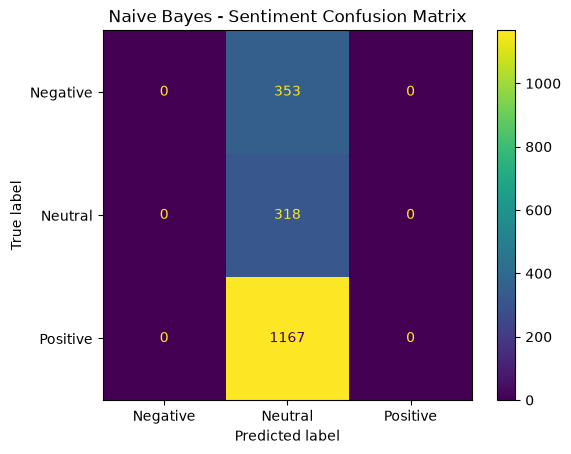

[[   0  353    0]
 [   0  318    0]
 [   0 1167    0]]


In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot()
plt.title("Naive Bayes - Sentiment Confusion Matrix")
plt.show()

print(cm)

In [19]:
label_check = reviews.groupby("cleaned_text")["sentiment"].nunique()

conflicting_reviews = label_check[label_check > 1]

print("Unique cleaned review texts:", reviews["cleaned_text"].nunique())
print("Texts with conflicting labels:", len(conflicting_reviews))

print("\nConflicting review texts:")
print(conflicting_reviews)

print("\nSentiment labels for conflicting reviews:")
print(
    reviews[reviews["cleaned_text"].isin(conflicting_reviews.index)]
    .groupby(["cleaned_text", "sentiment"])
    .size()
)

Unique cleaned review texts: 10
Texts with conflicting labels: 10

Conflicting review texts:
cleaned_text
amazing experience would order        3
food cold arrived late                3
food delicious delivery quick         3
fresh food fast delivery              3
good value money friendly delivery    3
great taste excellent service         3
not satisfied overall experience      3
order missing item                    3
order okay delivery took long         3
poor packaging disappointing food     3
Name: sentiment, dtype: int64

Sentiment labels for conflicting reviews:
cleaned_text                        sentiment
amazing experience would order      Negative      93
                                    Neutral       95
                                    Positive     379
food cold arrived late              Negative     100
                                    Neutral       86
                                    Positive     362
food delicious delivery quick       Negative     121
    

In [20]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_pred), 4))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_pred, zero_division=0))

SVM Accuracy: 0.6349

SVM Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       353
     Neutral       0.00      0.00      0.00       318
    Positive       0.63      1.00      0.78      1167

    accuracy                           0.63      1838
   macro avg       0.21      0.33      0.26      1838
weighted avg       0.40      0.63      0.49      1838



In [21]:
print("SVM prediction counts:")
print(pd.Series(svm_pred).value_counts())

print("\nActual test sentiment counts:")
print(y_test.value_counts())

SVM prediction counts:
Positive    1838
Name: count, dtype: int64

Actual test sentiment counts:
sentiment
Positive    1167
Negative     353
Neutral      318
Name: count, dtype: int64


In [22]:
unique_reviews = reviews[
    ["review_text", "cleaned_text"]
].drop_duplicates()

print(unique_reviews.to_string(index=False))

                                review_text                       cleaned_text
Good value for money and friendly delivery. good value money friendly delivery
 Not satisfied with the overall experience.   not satisfied overall experience
 Food was delicious and delivery was quick.      food delicious delivery quick
     Amazing experience, would order again!     amazing experience would order
 Order was okay but delivery took too long.      order okay delivery took long
               The order was missing items.                 order missing item
         Great taste and excellent service.      great taste excellent service
              Fresh food and fast delivery.           fresh food fast delivery
     Poor packaging and disappointing food.  poor packaging disappointing food
        The food was cold and arrived late.             food cold arrived late


In [23]:
sentiment_mapping = {
    "good value money friendly delivery": "Positive",
    "not satisfied overall experience": "Negative",
    "food delicious delivery quick": "Positive",
    "amazing experience would order": "Positive",
    "order okay delivery took long": "Neutral",
    "order missing item": "Negative",
    "great taste excellent service": "Positive",
    "fresh food fast delivery": "Positive",
    "poor packaging disappointing food": "Negative",
    "food cold arrived late": "Negative"
}

reviews["text_sentiment"] = reviews["cleaned_text"].map(sentiment_mapping)

print(reviews[["review_text", "sentiment", "text_sentiment"]].head(10))
print("\nNew text-based sentiment distribution:")
print(reviews["text_sentiment"].value_counts())

                                   review_text sentiment text_sentiment
0  Good value for money and friendly delivery.  Positive       Positive
1   Not satisfied with the overall experience.  Positive       Negative
2   Not satisfied with the overall experience.  Positive       Negative
3  Good value for money and friendly delivery.  Positive       Positive
4   Not satisfied with the overall experience.   Neutral       Negative
5   Food was delicious and delivery was quick.  Positive       Positive
6       Amazing experience, would order again!  Positive       Positive
7   Order was okay but delivery took too long.   Neutral        Neutral
8   Not satisfied with the overall experience.  Negative       Negative
9                 The order was missing items.  Positive       Negative

New text-based sentiment distribution:
text_sentiment
Positive    2864
Negative    2386
Neutral      603
Name: count, dtype: int64


In [24]:
label_check = reviews.groupby("cleaned_text")["text_sentiment"].nunique()

print("Review texts with more than one sentiment label:")
print(label_check[label_check > 1])

print("\nNumber of unique review texts:", reviews["cleaned_text"].nunique())

Review texts with more than one sentiment label:
Series([], Name: text_sentiment, dtype: int64)

Number of unique review texts: 10


In [27]:
from sklearn.model_selection import train_test_split

# Create the TF-IDF matrix
X = tfidf.fit_transform(reviews["cleaned_text"])

# Use the corrected sentiment labels
y = reviews["text_sentiment"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("TF-IDF matrix shape:", X.shape)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

TF-IDF matrix shape: (5853, 32)
Training samples: 4682
Testing samples: 1171

Training sentiment distribution:
text_sentiment
Positive    2291
Negative    1909
Neutral      482
Name: count, dtype: int64

Testing sentiment distribution:
text_sentiment
Positive    573
Negative    477
Neutral     121
Name: count, dtype: int64


In [28]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create and train the model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Predict sentiment for test reviews
nb_pred = nb_model.predict(X_test)

# Evaluate the model
print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

print("\nClassification Report:")
print(classification_report(y_test, nb_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred, labels=["Negative", "Neutral", "Positive"]))

Naive Bayes Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       477
     Neutral       1.00      1.00      1.00       121
    Positive       1.00      1.00      1.00       573

    accuracy                           1.00      1171
   macro avg       1.00      1.00      1.00      1171
weighted avg       1.00      1.00      1.00      1171


Confusion Matrix:
[[477   0   0]
 [  0 121   0]
 [  0   0 573]]


In [29]:
import pandas as pd

results = pd.DataFrame({
    "Review": reviews.loc[y_test.index, "review_text"].values,
    "Actual Sentiment": y_test.values,
    "Predicted Sentiment": nb_pred
})

results["Correct Prediction"] = (
    results["Actual Sentiment"] == results["Predicted Sentiment"]
)

print(results.head(20))

print("\nPrediction Summary:")
print(results["Correct Prediction"].value_counts())

print("\nIncorrect Predictions:")
print(results[results["Correct Prediction"] == False])

                                         Review Actual Sentiment  \
0            Great taste and excellent service.         Positive   
1                  The order was missing items.         Negative   
2                  The order was missing items.         Negative   
3        Amazing experience, would order again!         Positive   
4                  The order was missing items.         Negative   
5            Great taste and excellent service.         Positive   
6           The food was cold and arrived late.         Negative   
7                 Fresh food and fast delivery.         Positive   
8            Great taste and excellent service.         Positive   
9           The food was cold and arrived late.         Negative   
10   Food was delicious and delivery was quick.         Positive   
11  Good value for money and friendly delivery.         Positive   
12  Good value for money and friendly delivery.         Positive   
13       Amazing experience, would order again! 

In [1]:
import nltk

nltk.download("vader_lexicon")

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

print("VADER is ready!")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/nineleaps/nltk_data...


VADER is ready!


In [4]:
import pandas as pd

reviews = pd.read_csv("../data/raw/reviews.csv")

print(reviews.shape)
print(reviews.head())

(5853, 4)
   review_id  order_id  review_rating  \
0          1      9693              5   
1          2       285              5   
2          3      6824              4   
3          4      1590              4   
4          5      7808              3   

                                   review_text  
0  Good value for money and friendly delivery.  
1   Not satisfied with the overall experience.  
2   Not satisfied with the overall experience.  
3  Good value for money and friendly delivery.  
4   Not satisfied with the overall experience.  


In [5]:
reviews["vader_scores"] = reviews["review_text"].apply(
    lambda text: sia.polarity_scores(str(text))
)

print(reviews[["review_text", "vader_scores"]].head())

                                   review_text  \
0  Good value for money and friendly delivery.   
1   Not satisfied with the overall experience.   
2   Not satisfied with the overall experience.   
3  Good value for money and friendly delivery.   
4   Not satisfied with the overall experience.   

                                        vader_scores  
0  {'neg': 0.0, 'neu': 0.32, 'pos': 0.68, 'compou...  
1  {'neg': 0.318, 'neu': 0.682, 'pos': 0.0, 'comp...  
2  {'neg': 0.318, 'neu': 0.682, 'pos': 0.0, 'comp...  
3  {'neg': 0.0, 'neu': 0.32, 'pos': 0.68, 'compou...  
4  {'neg': 0.318, 'neu': 0.682, 'pos': 0.0, 'comp...  


In [6]:
reviews["negative"] = reviews["vader_scores"].apply(lambda x: x["neg"])
reviews["neutral"] = reviews["vader_scores"].apply(lambda x: x["neu"])
reviews["positive"] = reviews["vader_scores"].apply(lambda x: x["pos"])
reviews["compound"] = reviews["vader_scores"].apply(lambda x: x["compound"])

print(reviews[["review_text", "negative", "neutral", "positive", "compound"]].head())

                                   review_text  negative  neutral  positive  \
0  Good value for money and friendly delivery.     0.000    0.320      0.68   
1   Not satisfied with the overall experience.     0.318    0.682      0.00   
2   Not satisfied with the overall experience.     0.318    0.682      0.00   
3  Good value for money and friendly delivery.     0.000    0.320      0.68   
4   Not satisfied with the overall experience.     0.318    0.682      0.00   

   compound  
0    0.8176  
1   -0.3252  
2   -0.3252  
3    0.8176  
4   -0.3252  


In [7]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


reviews["vader_sentiment"] = reviews["compound"].apply(classify_sentiment)

print(reviews[["review_text", "compound", "vader_sentiment"]].head(10))

                                   review_text  compound vader_sentiment
0  Good value for money and friendly delivery.    0.8176        Positive
1   Not satisfied with the overall experience.   -0.3252        Negative
2   Not satisfied with the overall experience.   -0.3252        Negative
3  Good value for money and friendly delivery.    0.8176        Positive
4   Not satisfied with the overall experience.   -0.3252        Negative
5   Food was delicious and delivery was quick.    0.5719        Positive
6       Amazing experience, would order again!    0.6239        Positive
7   Order was okay but delivery took too long.    0.1154        Positive
8   Not satisfied with the overall experience.   -0.3252        Negative
9                 The order was missing items.   -0.2960        Negative


In [8]:
sentiment_counts = reviews["vader_sentiment"].value_counts()

print(sentiment_counts)

vader_sentiment
Positive    3467
Negative    1838
Neutral      548
Name: count, dtype: int64


In [9]:
sentiment_percentages = (
    reviews["vader_sentiment"].value_counts(normalize=True) * 100
).round(2)

print(sentiment_percentages)

vader_sentiment
Positive    59.23
Negative    31.40
Neutral      9.36
Name: proportion, dtype: float64


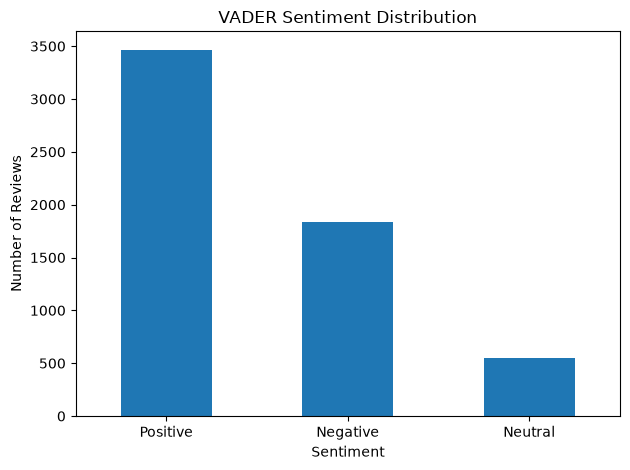

In [10]:
import matplotlib.pyplot as plt

sentiment_counts = reviews["vader_sentiment"].value_counts()

sentiment_counts.plot(kind="bar")
plt.title("VADER Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
print(pd.crosstab(
    reviews["text_sentiment"],
    reviews["vader_sentiment"],
    rownames=["Text-Based Label"],
    colnames=["VADER Prediction"]
))

KeyError: 'text_sentiment'

In [12]:
sentiment_mapping = {
    "Good value for money and friendly delivery.": "Positive",
    "Not satisfied with the overall experience.": "Negative",
    "Food was delicious and delivery was quick.": "Positive",
    "Amazing experience, would order again!": "Positive",
    "Order was okay but delivery took too long.": "Neutral",
    "The order was missing items.": "Negative",
    "Great taste and excellent service.": "Positive",
    "Fresh food and fast delivery.": "Positive",
    "Poor packaging and disappointing food.": "Negative",
    "The food was cold and arrived late.": "Negative"
}

reviews["text_sentiment"] = reviews["review_text"].map(sentiment_mapping)

print(reviews["text_sentiment"].value_counts())

text_sentiment
Positive    2864
Negative    2386
Neutral      603
Name: count, dtype: int64


In [14]:
print(pd.crosstab(
    reviews["text_sentiment"],
    reviews["vader_sentiment"],
    rownames=["Text-Based Label"],
    colnames=["VADER Prediction"]
))

VADER Prediction  Negative  Neutral  Positive
Text-Based Label                             
Negative              1838      548         0
Neutral                  0        0       603
Positive                 0        0      2864


In [15]:
disagreements = reviews[
    reviews["text_sentiment"] != reviews["vader_sentiment"]
]

print(
    disagreements[
        ["review_text", "text_sentiment", "compound", "vader_sentiment"]
    ].drop_duplicates()
)

                                   review_text text_sentiment  compound  \
7   Order was okay but delivery took too long.        Neutral    0.1154   
27         The food was cold and arrived late.       Negative    0.0000   

   vader_sentiment  
7         Positive  
27         Neutral  


In [16]:
agreement = (
    reviews["text_sentiment"] == reviews["vader_sentiment"]
).mean() * 100

print(f"VADER agreement with text-based labels: {agreement:.2f}%")

VADER agreement with text-based labels: 80.33%
